# BITS Pilani M.Tech AIML – Machine Learning Assignment 2

### Assignment workflow
1. Obtain and validate a public classification dataset (minimum 500 rows and 12 independent features).
2. Explore the dataset and prepare the data.
3. Train Logistic Regression, Decision Tree, KNN, Naive Bayes, and SVM on the same train/test split.
4. Evaluate Accuracy, AUC, Precision, Recall, F1 Score, and MCC.
5. Save models and supporting artifacts.
6. Generate a Streamlit application that loads saved models, accepts a labeled test CSV, and compares models without retraining.
7. Prepare README and deployment instructions.


## Dry Bean Multi-Class Classification

**Dataset:** UCI Dry Bean Dataset  
**Problem type:** Supervised multi-class classification  
**Target:** `Class` (seven dry bean varieties)



In [1]:
%pip install ucimlrepo pandas numpy matplotlib seaborn scikit-learn joblib streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import json
import warnings
from pathlib import Path

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix, classification_report
)

In [6]:
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
TEST_SIZE = 0.20

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"

for directory in (DATA_DIR, MODEL_DIR, REPORT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR.resolve())

Project directory: F:\GitWS\ml_classification_comparison


In [7]:
# Download the dataset from the UCI repository.
dry_bean = fetch_ucirepo(id=602)

X_raw = dry_bean.data.features.copy()
y_raw = dry_bean.data.targets.copy()

if isinstance(y_raw, pd.DataFrame):
    if y_raw.shape[1] != 1:
        raise ValueError(f"Expected one target column, received: {list(y_raw.columns)}")
    y_raw = y_raw.iloc[:, 0]

target_column = "Class"
X_raw.columns = [str(c).strip() for c in X_raw.columns]
y_raw = y_raw.astype(str).rename(target_column)

df = X_raw.copy()
df[target_column] = y_raw

# Convert feature columns to numeric, raising an error if unexpected text is present.
for col in X_raw.columns:
    df[col] = pd.to_numeric(df[col], errors="raise")

df.to_csv(DATA_DIR / "dry_bean.csv", index=False)

print("Dataset downloaded and saved.")
print("Shape:", df.shape)
print("Input features:", len(X_raw.columns))
print("Target classes:", sorted(df[target_column].unique()))
display(df.head())

Dataset downloaded and saved.
Shape: (13611, 17)
Input features: 16
Target classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 2. Validate dataset requirements

In [8]:
feature_columns = [c for c in df.columns if c != target_column]

validation = {
    "Number of rows": len(df),
    "Number of input features": len(feature_columns),
    "Number of target classes": df[target_column].nunique(),
    "Missing cells": int(df.isna().sum().sum()),
    "Duplicate rows": int(df.duplicated().sum())
}
display(pd.Series(validation, name="Value").to_frame())

assert len(df) >= 500, "Dataset must contain at least 500 instances."
assert len(feature_columns) >= 12, "Dataset must contain at least 12 independent input features."
assert df[target_column].nunique() >= 2, "At least two target classes are required."

print("Dataset meets the assignment's minimum size and feature requirements.")
print("\nFeature names:")
for i, name in enumerate(feature_columns, start=1):
    print(f"{i:2}. {name}")

,Value
Number of rows,13611
Number of input features,16
Number of target classes,7
Missing cells,0
Duplicate rows,68


Dataset meets the assignment's minimum size and feature requirements.

Feature names:
 1. Area
 2. Perimeter
 3. MajorAxisLength
 4. MinorAxisLength
 5. AspectRatio
 6. Eccentricity
 7. ConvexArea
 8. EquivDiameter
 9. Extent
10. Solidity
11. Roundness
12. Compactness
13. ShapeFactor1
14. ShapeFactor2
15. ShapeFactor3
16. ShapeFactor4


## 3. Data quality and exploratory data analysis


In [9]:
print("Missing values per column:")
display(df.isna().sum().to_frame("Missing values"))
print("Duplicate rows:", df.duplicated().sum())

print("\nTarget class counts:")
display(df[target_column].value_counts().rename_axis(target_column).to_frame("Count"))

Missing values per column:


,Missing values
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRatio,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


Duplicate rows: 68

Target class counts:


,Count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


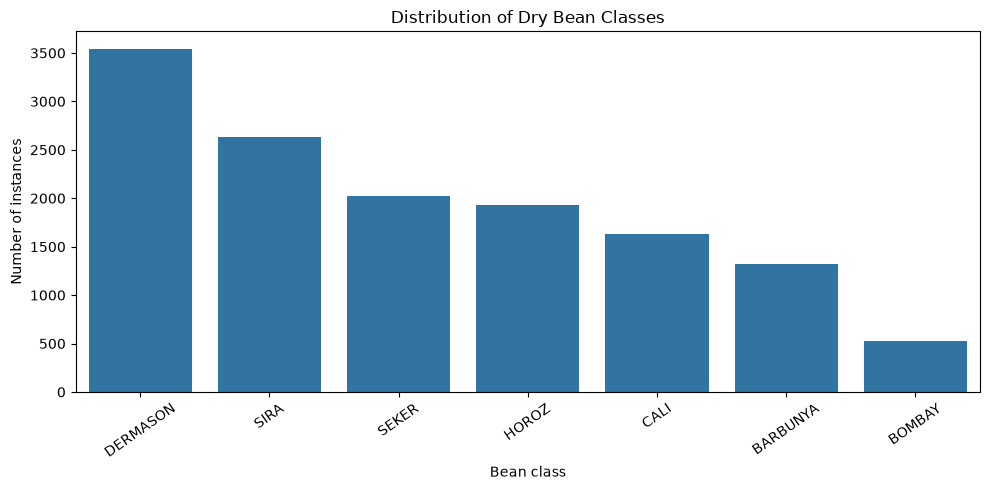

In [10]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x=target_column, order=df[target_column].value_counts().index)
plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean class")
plt.ylabel("Number of instances")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()